# 05 · Training the models (pipeline step 7)

Two small models are trained on every cross-validation fold:
- **GRU**, which reads the 20 frames one after the other (the main model),
- **MLP**, a simple network that looks at all 20 frames at once.

**Training setup:** AdamW optimiser, Huber loss on the normalised targets, and early stopping on a validation recording.
The seed is 42, so the results can be repeated.

**Input:** `data/interim/`. **Output:** the models of all folds in `models/cv_folds/`, `reports/training_summary.csv` and `reports/figures/training_curves.png`.

In [1]:
import time

import pandas as pd

from strikefit_ml.datasets import build_windows, make_splits
from strikefit_ml.ingestion import load_config, resolve
from strikefit_ml.models import build_model, n_params
from strikefit_ml.preprocessing import load_segments
from strikefit_ml.training import cross_validate, pick_device, plot_training_curves, summarise_histories

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
cfg = load_config()
figures = resolve(cfg, "figures_dir")
figures.mkdir(parents=True, exist_ok=True)
folds_dir = resolve(cfg, "models_dir") / "cv_folds"

segments = load_segments(resolve(cfg, "interim_dir"))
windows = build_windows(segments, cfg)
splits = make_splits(sorted(windows), cfg)
device = pick_device()
print("device:", device, "| folds:", [s.name for s in splits])
for kind in ("gru", "mlp"):
    count = n_params(build_model(kind, cfg))
    print(f"{kind}: {count:,} parameters", "(under the limit of %d)" % cfg["model"]["max_params"])

device: mps | folds: ['fold0', 'fold1', 'fold2', 'fold3', 'fold4']
gru: 19,236 parameters (under the limit of 200000)
mlp: 77,604 parameters (under the limit of 200000)


## Train every fold

In [2]:
histories, wall_clock = {}, {}
for kind in ("gru", "mlp"):
    start = time.perf_counter()
    histories[kind] = cross_validate(kind, cfg, windows, splits, folds_dir, device, progress=False)
    wall_clock[kind] = time.perf_counter() - start
    print(f"{kind}: {len(splits)} folds trained in {wall_clock[kind]:.1f} s")

gru: 5 folds trained in 17.9 s


mlp: 5 folds trained in 3.9 s


## Results of the training runs
`best_epoch` is the epoch with the lowest validation loss. The weights of that epoch are kept.

In [3]:
summary = summarise_histories(histories, splits)
summary

,model,fold,epochs_run,best_epoch,best_val_loss,final_train_loss,stopped_early,seconds,device
0,gru,fold0,35,27,0.212,0.123,True,4.910,mps
1,gru,fold1,26,18,0.151,0.125,True,3.095,mps
2,gru,fold2,19,11,0.271,0.133,True,2.303,mps
3,gru,fold3,21,13,0.177,0.132,True,3.080,mps
4,gru,fold4,24,16,0.196,0.127,True,3.664,mps
5,mlp,fold0,20,12,0.223,0.125,True,0.901,mps
6,mlp,fold1,16,8,0.160,0.121,True,0.604,mps
7,mlp,fold2,16,8,0.279,0.114,True,0.602,mps
8,mlp,fold3,19,11,0.180,0.117,True,0.935,mps
9,mlp,fold4,16,8,0.206,0.123,True,0.764,mps


In [4]:
overview = summary.groupby("model").agg(
    epochs_run_mean=("epochs_run", "mean"),
    best_val_loss_mean=("best_val_loss", "mean"),
    best_val_loss_std=("best_val_loss", "std"),
    seconds_total=("seconds", "sum"),
)
overview["wall_clock_s"] = pd.Series(wall_clock)
print(overview.round(3))

summary.to_csv(resolve(cfg, "reports_dir") / "training_summary.csv", index=False)
plot_training_curves({kind.upper(): runs for kind, runs in histories.items()}, figures / "training_curves.png")

       epochs_run_mean  best_val_loss_mean  best_val_loss_std  seconds_total  \
model                                                                          
gru             25.000               0.202              0.045         17.053   
mlp             17.400               0.210              0.046          3.806   

       wall_clock_s  
model                
gru          17.919  
mlp           3.870  


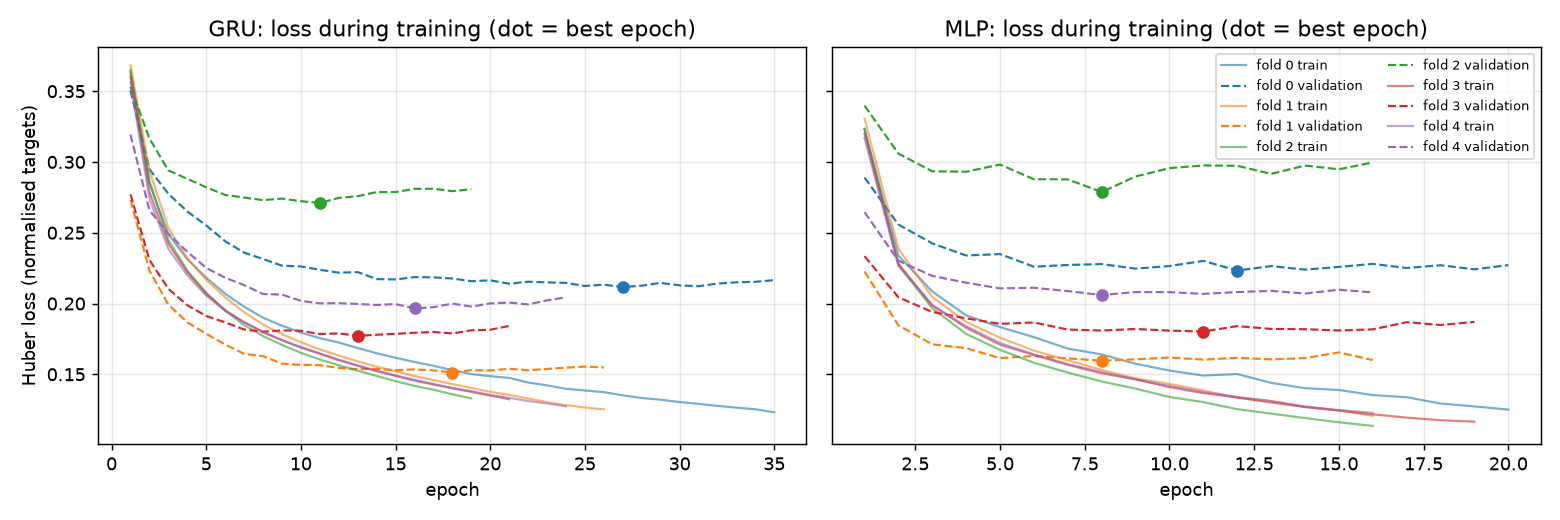

In [5]:
from IPython.display import Image

Image(figures / "training_curves.png")